In [30]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

print("SETUP OK")

TensorFlow: 2.21.0
NumPy: 2.4.6
SETUP OK


In [31]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


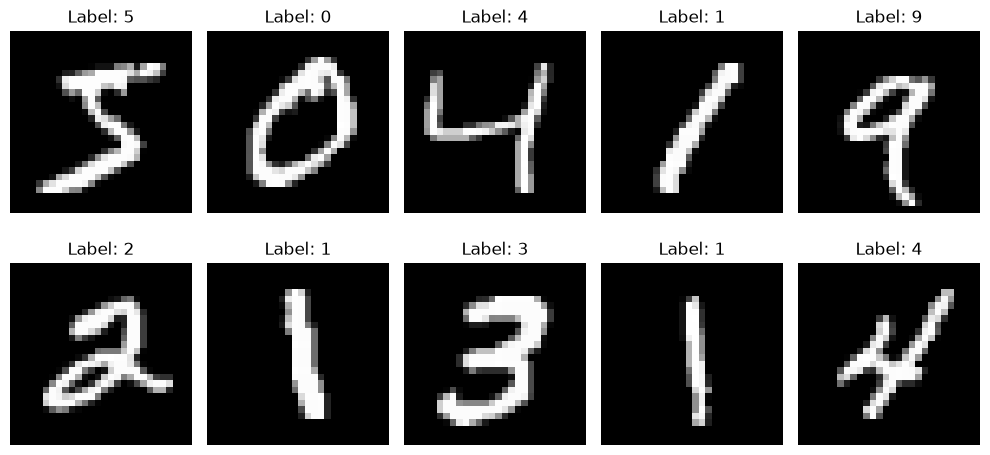

In [32]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel:", x_train.min())
print("Maximum pixel:", x_train.max())

Minimum pixel: 0.0
Maximum pixel: 1.0


In [34]:
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training shape:", x_train.shape)
print("Test shape:", x_test.shape)

Training shape: (60000, 28, 28, 1)
Test shape: (10000, 28, 28, 1)


In [35]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - accuracy: 0.9117 - loss: 0.2860 - val_accuracy: 0.9832 - val_loss: 0.0585
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - accuracy: 0.9765 - loss: 0.0773 - val_accuracy: 0.9892 - val_loss: 0.0405
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 22s 52ms/step - accuracy: 0.9828 - loss: 0.0553 - val_accuracy: 0.9898 - val_loss: 0.0386
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - accuracy: 0.9866 - loss: 0.0433 - val_accuracy: 0.9892 - val_loss: 0.0413
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 45ms/step - accuracy: 0.9886 - loss: 0.0370 - val_accuracy: 0.9907 - val_loss: 0.0327
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - accuracy: 0.9900 - loss: 0.0318 - val_accuracy: 0.9912 - val_loss: 0.0345
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - accuracy: 0.9924 - loss: 0.0256 - val_accuracy: 0.9905 - val_loss: 0.0342
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - accuracy: 0.9927 - loss: 0.0232 - 

In [37]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9913 - loss: 0.0257
Test Loss: 0.0257
Test Accuracy: 99.13%


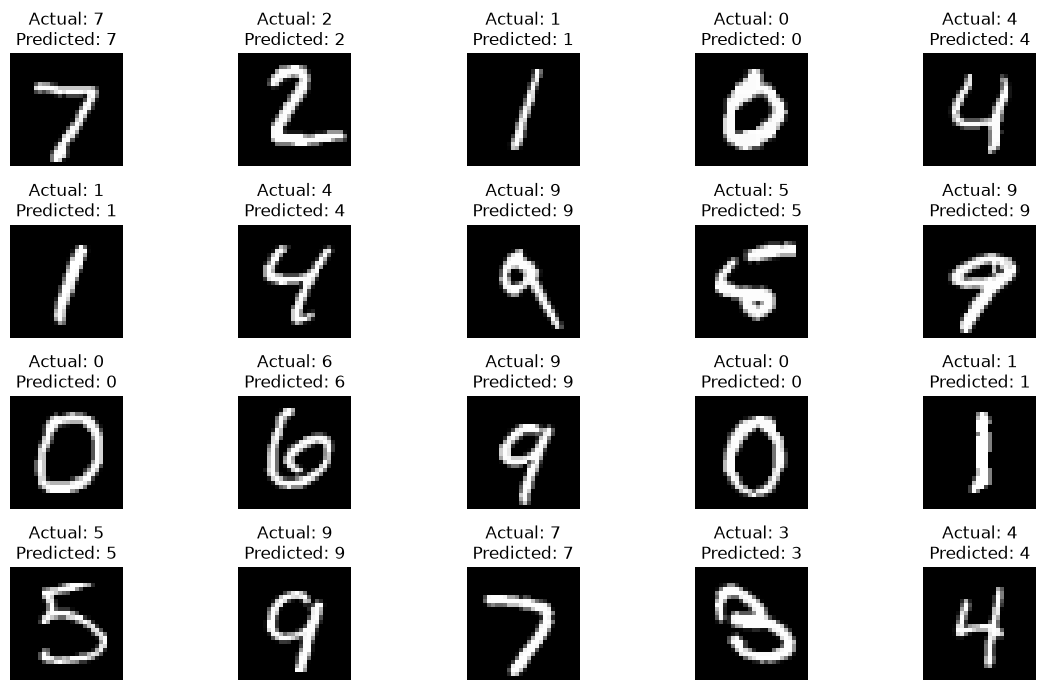

In [38]:
predictions = model.predict(x_test[:20], verbose=0)

predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 7))

for i in range(20):
    plt.subplot(4, 5, i + 1)

    plt.imshow(
        x_test[i].squeeze(),
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predicted_labels[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [39]:
model.save("mnist_handwritten_digit_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [40]:
loaded_model = tf.keras.models.load_model(
    "mnist_handwritten_digit_model.keras"
)

loaded_loss, loaded_accuracy = loaded_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(
    f"Loaded Model Accuracy: "
    f"{loaded_accuracy * 100:.2f}%"
)

Loaded Model Accuracy: 99.13%


In [41]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9913 - loss: 0.0257
Test Loss: 0.0257
Test Accuracy: 99.13%


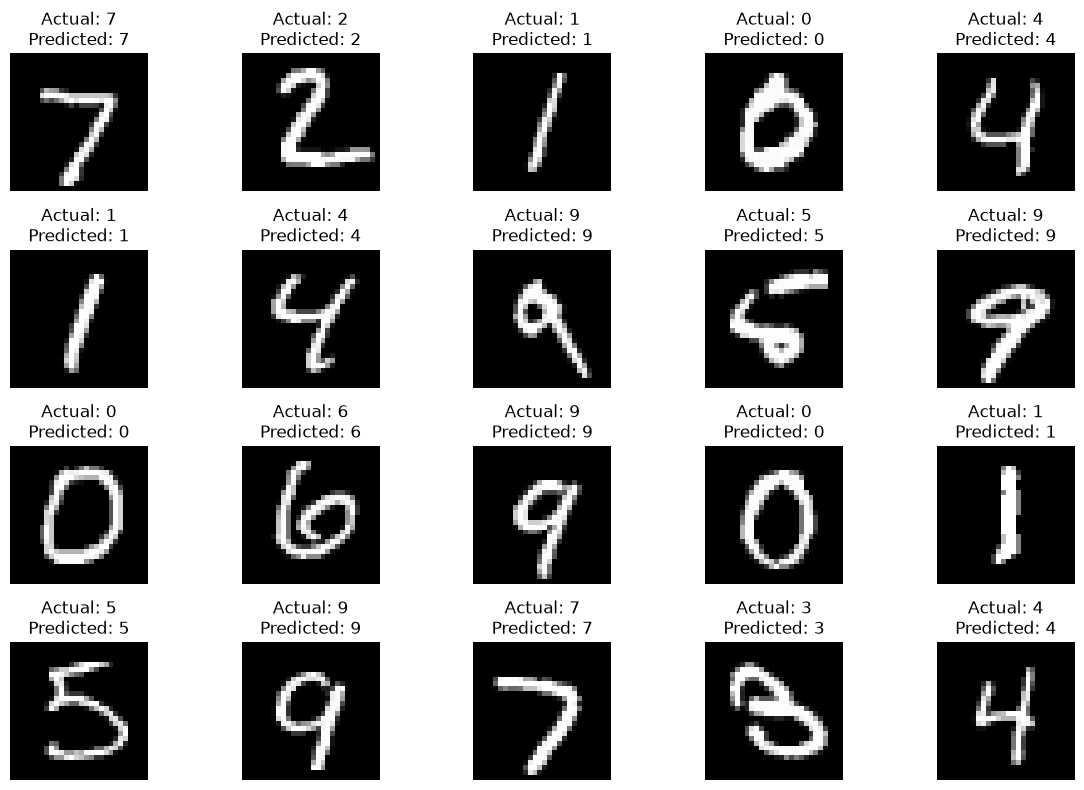

In [42]:
predictions = model.predict(x_test[:20], verbose=0)

predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)

    plt.imshow(x_test[i].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predicted_labels[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

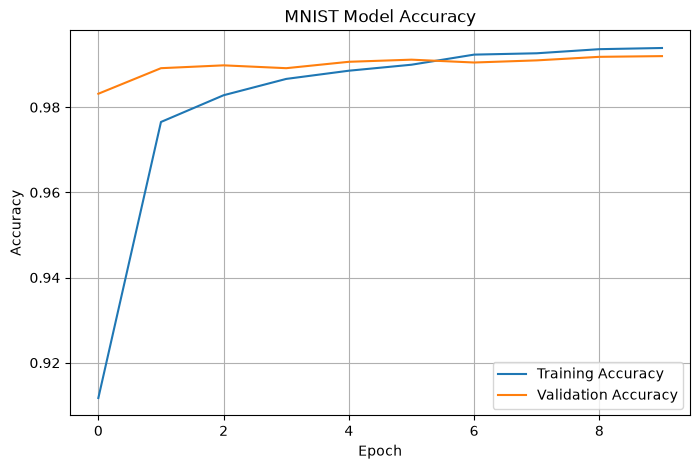

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MNIST Model Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [44]:
MODEL_PATH = "mnist_handwritten_digit_model.keras"

model.save(MODEL_PATH)

print("Model saved successfully!")
print("File:", MODEL_PATH)

Model saved successfully!
File: mnist_handwritten_digit_model.keras


In [45]:
MODEL_PATH = "mnist_handwritten_digit_model.keras"

model.save(MODEL_PATH)

print("Model saved successfully!")
print("File:", MODEL_PATH)

Model saved successfully!
File: mnist_handwritten_digit_model.keras


In [46]:
loaded_model = tf.keras.models.load_model(
    "mnist_handwritten_digit_model.keras"
)

loaded_loss, loaded_accuracy = loaded_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(
    f"Saved Model Test Accuracy: "
    f"{loaded_accuracy * 100:.2f}%"
)

Saved Model Test Accuracy: 99.13%


Actual Digit:    6
Predicted Digit: 6
Confidence:     100.00%


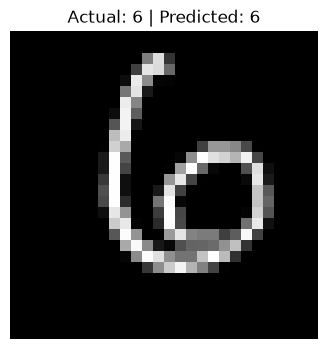

In [47]:
index = 100

image = x_test[index]

prediction = loaded_model.predict(
    image[np.newaxis, ...],
    verbose=0
)

predicted_digit = np.argmax(prediction)

confidence = np.max(prediction) * 100

print("Actual Digit:   ", y_test[index])
print("Predicted Digit:", predicted_digit)
print(f"Confidence:     {confidence:.2f}%")

plt.figure(figsize=(4, 4))
plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Actual: {y_test[index]} | "
    f"Predicted: {predicted_digit}"
)
plt.axis("off")
plt.show()

In [48]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "mnist_handwritten_digit_model.keras"
)

print("Original model loaded successfully!")

Original model loaded successfully!


In [49]:
for i, layer in enumerate(model.layers):
    print(i, layer.name, layer.trainable)

0 conv2d_2 True
1 max_pooling2d_2 True
2 conv2d_3 True
3 max_pooling2d_3 True
4 flatten_1 True
5 dense_2 True
6 dropout_1 True
7 dense_3 True


In [50]:
for layer in model.layers:
    if isinstance(layer, (tf.keras.layers.Conv2D,
                          tf.keras.layers.MaxPooling2D)):
        layer.trainable = False

print("Convolution layers frozen.")

Convolution layers frozen.


In [51]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning.")

Model recompiled for fine-tuning.


In [52]:
fine_tune_history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9967 - loss: 0.0113 - val_accuracy: 0.9937 - val_loss: 0.0296
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.9971 - loss: 0.0090 - val_accuracy: 0.9933 - val_loss: 0.0288
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9974 - loss: 0.0084 - val_accuracy: 0.9933 - val_loss: 0.0300
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9978 - loss: 0.0072 - val_accuracy: 0.9935 - val_loss: 0.0297
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9978 - loss: 0.0068 - val_accuracy: 0.9935 - val_loss: 0.0309


In [53]:
fine_loss, fine_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print(f"Fine-tuned Test Accuracy: {fine_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9925 - loss: 0.0230
Fine-tuned Test Accuracy: 99.25%


In [54]:
for layer in model.layers:
    if isinstance(layer, tf.keras.layers.Conv2D):
        layer.trainable = True

print("Convolution layers unfrozen for deeper fine-tuning.")

Convolution layers unfrozen for deeper fine-tuning.


In [55]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [56]:
deep_fine_tune_history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 53ms/step - accuracy: 0.9979 - loss: 0.0066 - val_accuracy: 0.9933 - val_loss: 0.0310
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 55ms/step - accuracy: 0.9983 - loss: 0.0061 - val_accuracy: 0.9933 - val_loss: 0.0312
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step - accuracy: 0.9983 - loss: 0.0057 - val_accuracy: 0.9933 - val_loss: 0.0315


In [57]:
final_loss, final_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print(f"Final Fine-Tuned Accuracy: {final_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9932 - loss: 0.0229
Final Fine-Tuned Accuracy: 99.32%


In [58]:
model.save(
    "mnist_handwritten_digit_fine_tuned.keras"
)

print("Fine-tuned model saved successfully!")

Fine-tuned model saved successfully!
